# Parte 2 — Análise Preditiva: Previsão de Churn

**Objetivo:** treinar um modelo que estime a probabilidade de um cliente cancelar, para que a operadora aja *antes* do cancelamento.

- **Problema:** classificação binária (`churn` = Sim/Não)
- **Divisão:** 80% treino / 20% teste, estratificada pelo alvo
- **Modelos comparados:** Regressão Logística, Random Forest e Gradient Boosting
- O código de treino fica em `src/treinar_modelo.py`; este notebook o executa e analisa os resultados.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # permite importar src/ a partir de notebooks/

import pandas as pd
import matplotlib.pyplot as plt
from src.dados import carregar_dados, NUMERICAS, CATEGORICAS, ROTULOS
pd.set_option("display.max_columns", 30)
import json, joblib
from src.treinar_modelo import treinar
from src.dados import CAMINHO_METRICAS

## 1. Pré-processamento
Feito dentro de um `Pipeline` do scikit-learn (assim o modelo salvo já recebe os dados "crus" na dashboard):
- numéricas → `StandardScaler`
- categóricas → `OneHotEncoder(handle_unknown="ignore")`

Como a base é desbalanceada, Regressão Logística e Random Forest usam `class_weight="balanced"`.

## 2. Treino e comparação

In [2]:
modelo = treinar()
met = json.load(open(CAMINHO_METRICAS, encoding="utf-8"))
tabela = pd.DataFrame({n: {k: v[k] for k in ["acuracia", "precisao", "recall", "f1", "roc_auc"]}
                       for n, v in met["resultados"].items()}).T
tabela.round(3)

Regressão Logística    AUC=0.842  recall=0.783  F1=0.614  acurácia=0.738


Random Forest          AUC=0.843  recall=0.794  F1=0.628  acurácia=0.750


Gradient Boosting      AUC=0.844  recall=0.524  F1=0.588  acurácia=0.805

Modelo escolhido: Random Forest


,acuracia,precisao,recall,f1,roc_auc
Regressão Logística,0.738,0.504,0.783,0.614,0.842
Random Forest,0.750,0.519,0.794,0.628,0.843
Gradient Boosting,0.805,0.669,0.524,0.588,0.844


As três AUCs ficam praticamente empatadas (~0,84). O Gradient Boosting tem a maior acurácia, mas identifica só ~52% dos clientes que cancelam. Em churn, **deixar de identificar quem vai sair (falso negativo) custa mais** do que um alarme falso (no máximo um desconto oferecido a quem ficaria). Por isso o critério escolhido foi o **F1**, que equilibra precisão e recall.

In [3]:
print("Modelo escolhido:", met["modelo_escolhido"])

Modelo escolhido: Random Forest


## 3. Curva ROC e matriz de confusão

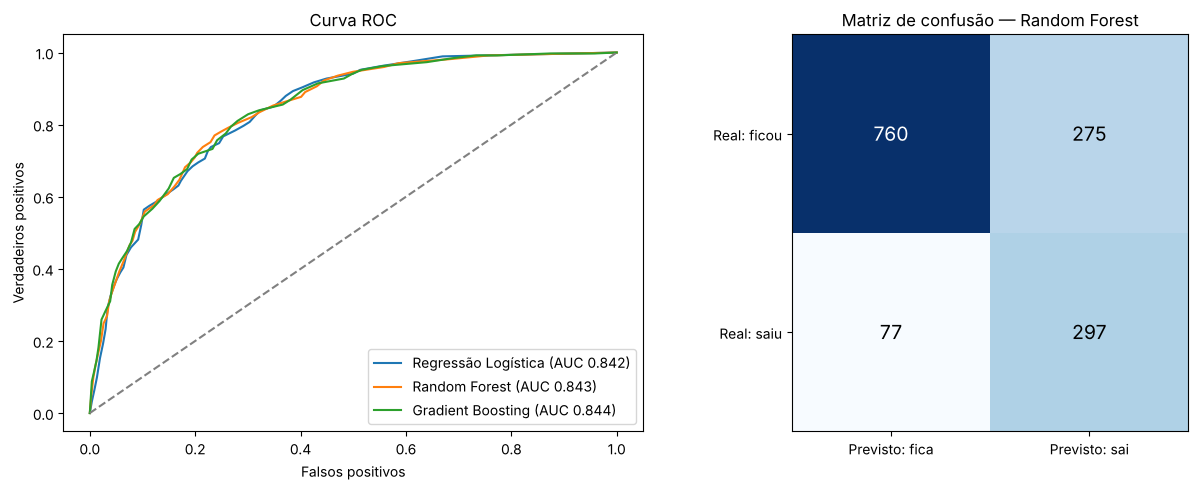

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for n, v in met["resultados"].items():
    a1.plot(v["roc"]["fpr"], v["roc"]["tpr"], label=f"{n} (AUC {v['roc_auc']:.3f})")
a1.plot([0, 1], [0, 1], "--", color="gray"); a1.legend(); a1.set_title("Curva ROC")
a1.set_xlabel("Falsos positivos"); a1.set_ylabel("Verdadeiros positivos")

mc = met["resultados"][met["modelo_escolhido"]]["matriz_confusao"]
a2.imshow(mc, cmap="Blues")
for i in range(2):
    for j in range(2):
        a2.text(j, i, mc[i][j], ha="center", va="center", fontsize=14, color="white" if mc[i][j] > 500 else "black")
a2.set_xticks([0, 1], ["Previsto: fica", "Previsto: sai"]); a2.set_yticks([0, 1], ["Real: ficou", "Real: saiu"])
a2.set_title(f"Matriz de confusão — {met['modelo_escolhido']}")
plt.tight_layout(); plt.show()

## 4. Importância das variáveis

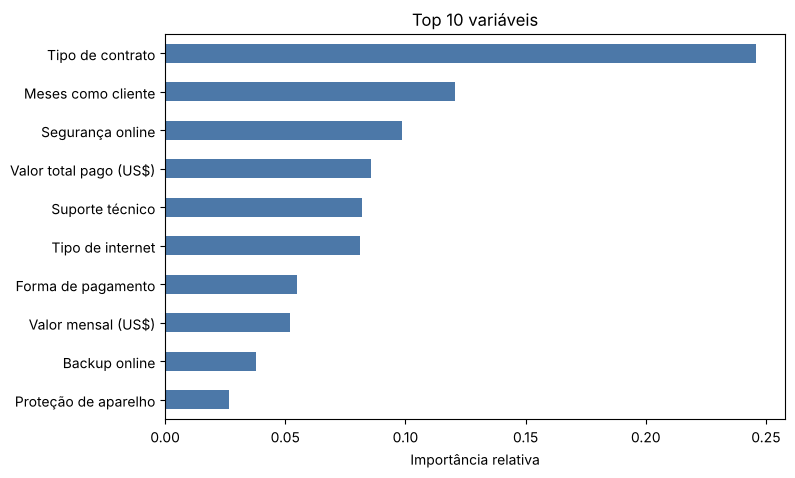

In [5]:
imp = pd.DataFrame(met["importancias"], columns=["variavel", "importancia"])
imp["variavel"] = imp["variavel"].map(ROTULOS)
imp.head(10).iloc[::-1].plot.barh(x="variavel", y="importancia", legend=False, color="#4C78A8", figsize=(8, 5))
plt.title("Top 10 variáveis"); plt.xlabel("Importância relativa"); plt.ylabel(""); plt.show()

## 5. Exemplo de previsão

In [6]:
exemplo = pd.DataFrame([{
    "meses_contrato": 3, "valor_mensal": 90.0, "valor_total": 270.0,
    "genero": "Feminino", "idoso": "Não", "tem_parceiro": "Não", "tem_dependentes": "Não",
    "servico_telefone": "Sim", "multiplas_linhas": "Não", "tipo_internet": "Fibra óptica",
    "seguranca_online": "Não", "backup_online": "Não", "protecao_aparelho": "Não",
    "suporte_tecnico": "Não", "streaming_tv": "Sim", "streaming_filmes": "Sim",
    "tipo_contrato": "Mensal", "fatura_digital": "Sim", "forma_pagamento": "Boleto eletrônico",
}])
print(f"Probabilidade de churn: {modelo.predict_proba(exemplo[NUMERICAS + CATEGORICAS])[0, 1]:.1%}")

Probabilidade de churn: 88.5%


## 6. Conclusões

- O modelo escolhido identifica cerca de **8 em cada 10 clientes que vão cancelar**, com ROC-AUC ≈ 0,84.
- As variáveis mais importantes (**tipo de contrato, tempo como cliente, valores pagos e tipo de internet**) confirmam a análise exploratória da Parte 1.
- **Uso prático:** ordenar a base pela probabilidade prevista e direcionar ações de retenção (migração para contrato anual, bônus de suporte técnico, incentivo a pagamento automático) aos clientes de maior risco.
- O modelo salvo (`models/modelo_churn.joblib`) é usado no **simulador** da dashboard (Checkpoint 3).